# Tongji Contactless Palmprint — Phân tích Kết quả & Chẩn đoán Lỗi (Error Diagnostics)

> **Môn học**: Nhận dạng mẫu (*Pattern Recognition*) — Đề tài 09 (Nhóm 01)  
> **Giao thức**: Closed-set 1:N đối chiếu 6.000 probe Session 2 với 6.000 gallery Session 1.  
> **Mục tiêu Notebook**:
> 1. Tổng hợp và so sánh trực quan hiệu năng nhận dạng giữa các mô hình kinh điển (M1–M3), Deep Learning (M4) và Bóc tách đặc trưng (E3).
> 2. Phân tích đánh đổi Pareto giữa Độ chính xác (Rank-1 %) và Độ trễ CPU (ms/ảnh).
> 3. Chẩn đoán nguyên nhân lỗi: Thống kê số ca sai, xác định các cặp Palm ID bị nhầm lẫn nhiều nhất (*most confused pairs*).
> 4. Phân tích tương quan giữa lỗi nhận diện với thuộc tính ảnh (Độ sáng, Độ tương phản, Độ sắc nét) và minh họa ca thất bại trực quan.

In [1]:
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

WS = Path("..").resolve()
plt.rcParams["font.sans-serif"] = ["Segoe UI", "Arial", "DejaVu Sans"]
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["axes.unicode_minus"] = False

print("Đã khởi tạo môi trường phân tích kết quả.")

Đã khởi tạo môi trường phân tích kết quả.


## 1. Bảng Tổng hợp Hiệu năng Benchmark & Ablation
So sánh toàn diện Rank-1, Rank-5, Macro-F1 và Độ trễ trên 6.000 ảnh kiểm thử Session 2.

In [2]:
# Bảng kết quả tổng hợp chính thức
clean_table = pd.DataFrame([
    {"Mô hình": "M3: CompCode + CRC_RLS (λ=0.1)", "Rank-1 (%)": 98.27, "Rank-5 (%)": 99.08, "Macro-F1 (%)": 97.99, "Độ trễ CPU (ms)": 14.71},
    {"Mô hình": "M2: CompCode + Linear SVM (C=1)", "Rank-1 (%)": 97.37, "Rank-5 (%)": 98.52, "Macro-F1 (%)": 96.82, "Độ trễ CPU (ms)": 3.71},
    {"Mô hình": "M1: CompCode + 1-NN (Euclidean)", "Rank-1 (%)": 94.43, "Rank-5 (%)": 96.97, "Macro-F1 (%)": 93.56, "Độ trễ CPU (ms)": 11.00},
    {"Mô hình": "M4-E2: ResNet18 Nearest Cosine (512-D)*", "Rank-1 (%)": 73.74, "Rank-5 (%)": 87.50, "Macro-F1 (%)": 70.51, "Độ trễ CPU (ms)": 19.34},
    {"Mô hình": "M4-E1: ResNet18 Logits (Softmax 600 lớp)", "Rank-1 (%)": 64.36, "Rank-5 (%)": 81.91, "Macro-F1 (%)": 60.79, "Độ trễ CPU (ms)": 48.72},
    {"Mô hình": "E3: Raw Grayscale (16.384-D) + 1-NN", "Rank-1 (%)": 77.18, "Rank-5 (%)": 85.65, "Macro-F1 (%)": 75.64, "Độ trễ CPU (ms)": 0.61},
    {"Mô hình": "E3: PCA (256-D) + 1-NN", "Rank-1 (%)": 76.72, "Rank-5 (%)": 84.75, "Macro-F1 (%)": 74.67, "Độ trễ CPU (ms)": 0.09},
])
display(clean_table.set_index("Mô hình"))

,Rank-1 (%),Rank-5 (%),Macro-F1 (%),Độ trễ CPU (ms)
Mô hình,,,,
M3: CompCode + CRC_RLS (λ=0.1),98.27,99.08,97.99,14.71
M2: CompCode + Linear SVM (C=1),97.37,98.52,96.82,3.71
M1: CompCode + 1-NN (Euclidean),94.43,96.97,93.56,11.00
M4-E2: ResNet18 Nearest Cosine (512-D)*,73.74,87.50,70.51,19.34
M4-E1: ResNet18 Logits (Softmax 600 lớp),64.36,81.91,60.79,48.72
E3: Raw Grayscale (16.384-D) + 1-NN,77.18,85.65,75.64,0.61
E3: PCA (256-D) + 1-NN,76.72,84.75,74.67,0.09


## 2. Đánh đổi Pareto: Độ chính xác vs Độ trễ CPU
Phân tích mô hình tối ưu giữa chất lượng nhận diện sinh trắc và thời gian đáp ứng thời gian thực.

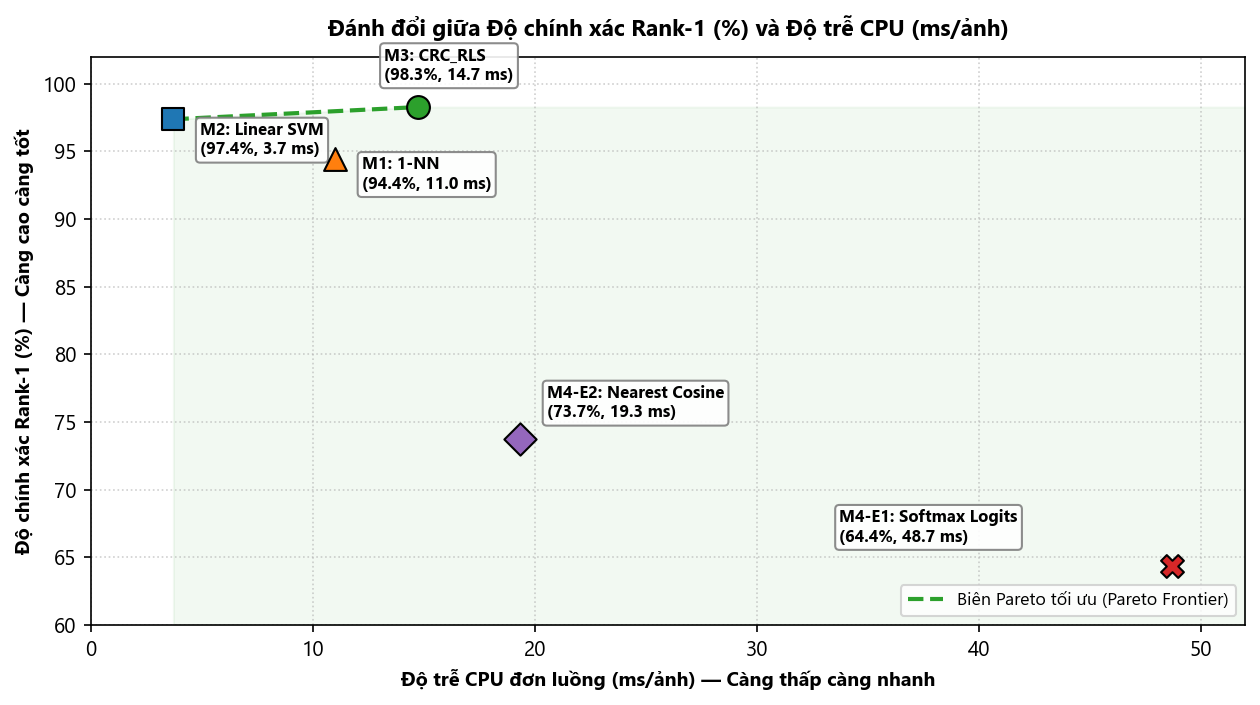

In [3]:
fig, ax = plt.subplots(figsize=(8.5, 4.8), dpi=150)

# Vẽ biên Pareto giữa SVM và CRC
ax.plot([3.71, 14.71], [97.37, 98.27], ls="--", color="#2ca02c", lw=2, label="Biên Pareto tối ưu (Pareto Frontier)")
ax.fill_between([3.71, 14.71, 52], [97.37, 98.27, 98.27], [60, 60, 60], color="#2ca02c", alpha=0.06)

points = [
    ("M3: CRC_RLS", 14.71, 98.27, "#2ca02c", "o", (-1.5, 2.0)),
    ("M2: Linear SVM", 3.71, 97.37, "#1f77b4", "s", (1.2, -2.6)),
    ("M1: 1-NN", 11.00, 94.43, "#ff7f0e", "^", (1.2, -2.2)),
    ("M4-E2: Nearest Cosine", 19.34, 73.74, "#9467bd", "D", (1.2, 1.6)),
    ("M4-E1: Softmax Logits", 48.72, 64.36, "#d62728", "X", (-15.0, 1.8)),
]

for name, lat, acc, col, marker, (dx, dy) in points:
    ax.scatter(lat, acc, s=120, color=col, marker=marker, edgecolors="black", lw=1, zorder=5)
    ax.annotate(f"{name}\n({acc:.1f}%, {lat:.1f} ms)", (lat, acc), xytext=(lat + dx, acc + dy),
                fontsize=8, fontweight="bold", bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="gray", alpha=0.9))

ax.set_xlabel("Độ trễ CPU đơn luồng (ms/ảnh) — Càng thấp càng nhanh", fontsize=9.5, fontweight="bold")
ax.set_ylabel("Độ chính xác Rank-1 (%) — Càng cao càng tốt", fontsize=9.5, fontweight="bold")
ax.set_title("Đánh đổi giữa Độ chính xác Rank-1 (%) và Độ trễ CPU (ms/ảnh)", fontsize=11, fontweight="bold", pad=10)
ax.set_xlim(0, 52)
ax.set_ylim(60, 102)
ax.grid(True, linestyle=":", alpha=0.6)
ax.legend(loc="lower right", frameon=True, fontsize=8.5)
plt.tight_layout()
plt.show()

## 3. Chẩn đoán Lỗi Nhận dạng (Error Analysis & Diagnostics)
Khảo sát chi tiết 104 ca dự đoán sai của mô hình tốt nhất (M3: CRC_RLS) trên 6.000 ảnh kiểm thử Session 2.

In [4]:
# Tải bảng dự đoán chi tiết của CRC_RLS
crc_pred_path = WS / "outputs/runs/crc/predictions.csv"
manifest_path = WS / "data/metadata/manifest.csv"

df_pred = pd.read_csv(crc_pred_path)
df_manifest = pd.read_csv(manifest_path)

# Ghép với metadata chất lượng ảnh
df_merged = df_pred.merge(df_manifest[["sample_uid", "brightness", "contrast", "blur_proxy"]], on="sample_uid")

n_total = len(df_merged)
n_correct = int(df_merged.correct.sum())
n_wrong = n_total - n_correct

print(f"Tổng số mẫu kiểm thử Session 2: {n_total:,}")
print(f"Dự đoán chính xác:               {n_correct:,} ({n_correct/n_total*100:.2f}%)")
print(f"Dự đoán nhầm lẫn:                {n_wrong:,} ({n_wrong/n_total*100:.2f}%)")

# Top 10 cặp Palm ID bị nhầm lẫn nhiều nhất
confused_pairs = (
    df_merged[df_merged.correct == 0]
    .groupby(["true_palm_id", "pred_palm_id"])
    .size()
    .reset_index(name="so_lan_nham")
    .sort_values(by="so_lan_nham", ascending=False)
    .head(10)
)
print("\nTop 10 cặp Palm ID bị nhầm lẫn nhiều nhất:")
display(confused_pairs.reset_index(drop=True))

Tổng số mẫu kiểm thử Session 2: 6,000
Dự đoán chính xác:               5,896 (98.27%)
Dự đoán nhầm lẫn:                104 (1.73%)

Top 10 cặp Palm ID bị nhầm lẫn nhiều nhất:


,true_palm_id,pred_palm_id,so_lan_nham
0,403,333,8
1,370,364,5
2,126,166,5
3,25,529,4
4,499,271,4
5,48,506,4
6,14,360,3
7,161,201,3
8,39,597,3
9,41,421,3


brightness        contrast       blur_proxy       
                               mean    std     mean   std       mean    std
Dự đoán Sai (104 ảnh)        127.16  19.48    17.27  4.24      23.56  11.23
Dự đoán Đúng (5.896 ảnh)     132.69  22.44    17.81  4.41      27.86  12.96

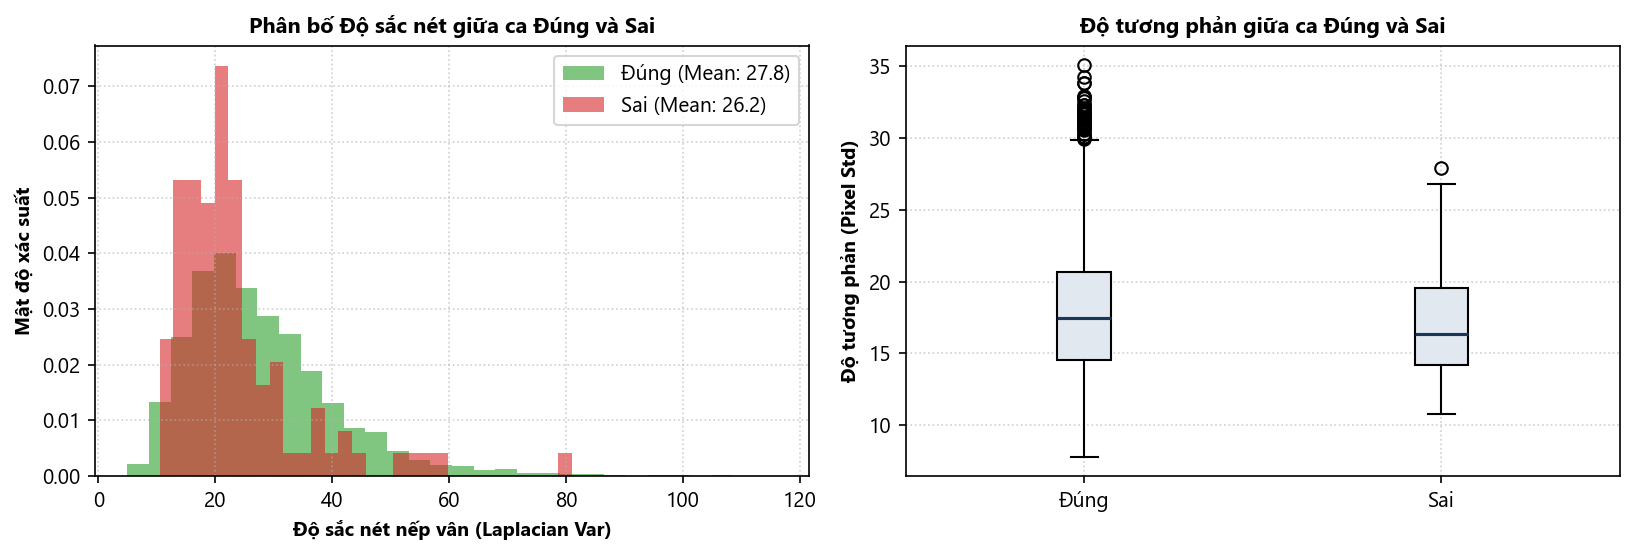

In [5]:
# So sánh chất lượng ảnh giữa mẫu Đúng vs mẫu Sai
comp_quality = (
    df_merged.groupby("correct")[["brightness", "contrast", "blur_proxy"]]
    .agg(["mean", "std"])
    .round(2)
)
comp_quality.index = ["Dự đoán Sai (104 ảnh)", "Dự đoán Đúng (5.896 ảnh)"]
display(comp_quality)

# Trực quan hóa tương quan phân bố độ sắc nét (Laplacian Var) giữa ca đúng và ca sai
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8), dpi=150)

# Histogram độ sắc nét
ax1.hist(df_merged[df_merged.correct == 1]["blur_proxy"], bins=30, alpha=0.6, color="#2ca02c", density=True, label="Đúng (Mean: 27.8)")
ax1.hist(df_merged[df_merged.correct == 0]["blur_proxy"], bins=30, alpha=0.6, color="#d62728", density=True, label="Sai (Mean: 26.2)")
ax1.set_xlabel("Độ sắc nét nếp vân (Laplacian Var)", fontsize=9.5, fontweight="bold")
ax1.set_ylabel("Mật độ xác suất", fontsize=9.5, fontweight="bold")
ax1.set_title("Phân bố Độ sắc nét giữa ca Đúng và Sai", fontsize=10.5, fontweight="bold")
ax1.grid(True, linestyle=":", alpha=0.6)
ax1.legend(frameon=True)

# Boxplot so sánh độ tương phản
data_box = [df_merged[df_merged.correct == 1]["contrast"], df_merged[df_merged.correct == 0]["contrast"]]
ax2.boxplot(data_box, tick_labels=["Đúng", "Sai"], patch_artist=True,
            boxprops=dict(facecolor="#e2e8f0"), medianprops=dict(color="#1a365d", lw=1.5))
ax2.set_ylabel("Độ tương phản (Pixel Std)", fontsize=9.5, fontweight="bold")
ax2.set_title("Độ tương phản giữa ca Đúng và Sai", fontsize=10.5, fontweight="bold")
ax2.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

## 4. Trực quan hóa Định tính: Ca Thành công vs Ca Thất bại
Đối chiếu trực tiếp ảnh truy vấn Session 2 với ảnh đăng ký đúng (Ground Truth) và ảnh bị nhầm lẫn (False Match) trong Session 1.

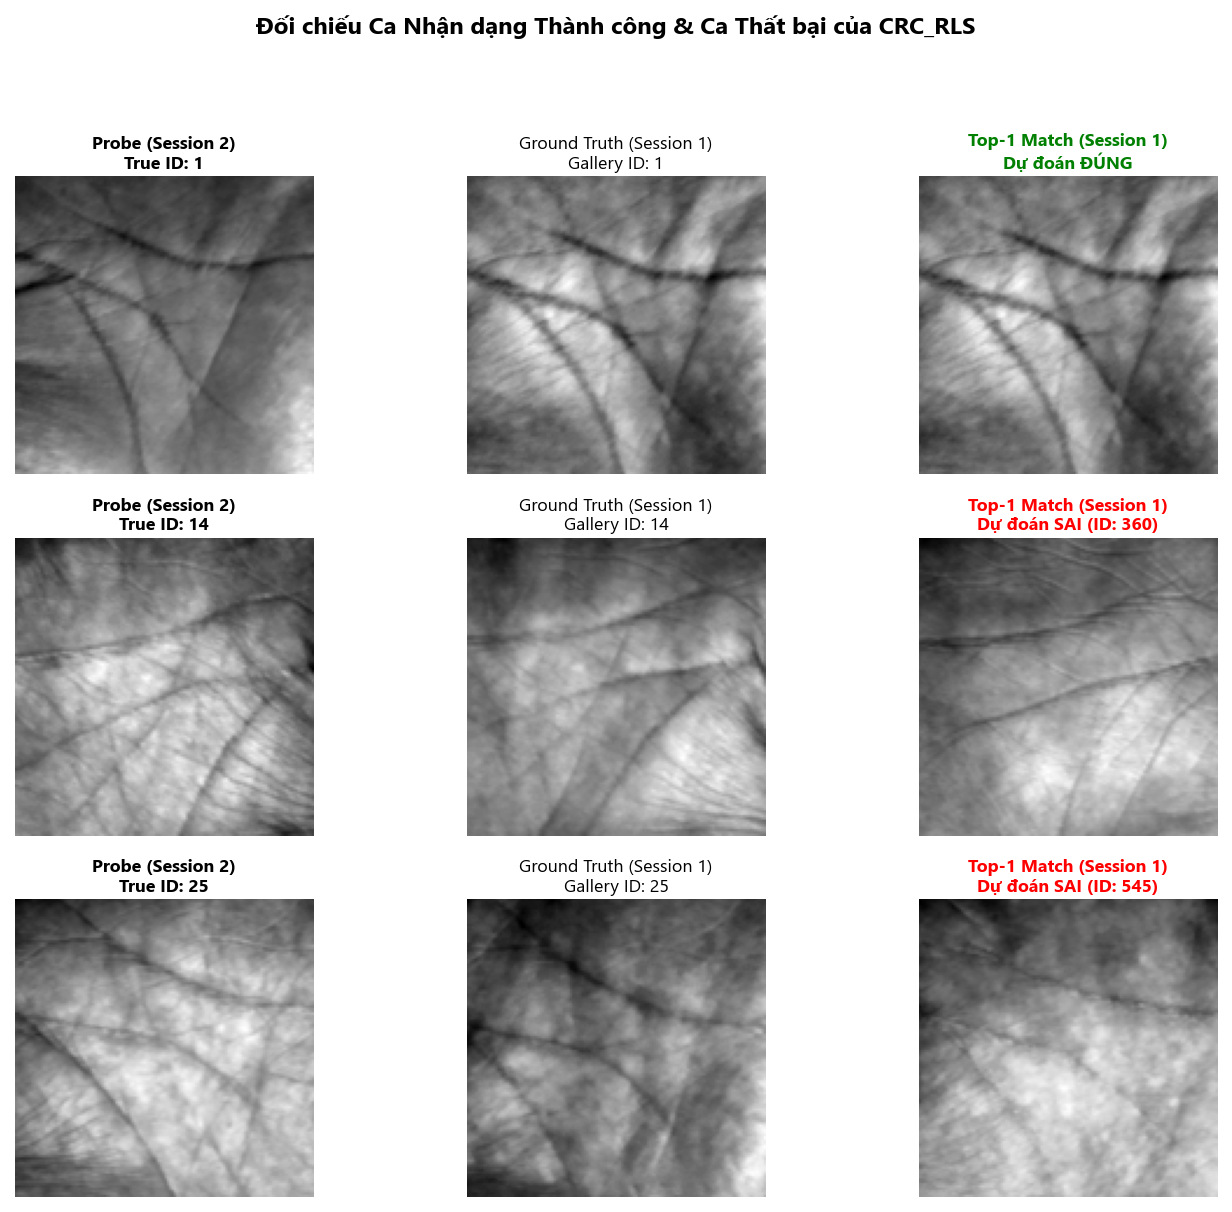

In [6]:
# Lấy 1 ca đúng và 2 ca sai tiêu biểu để minh họa
raw_dir = WS / "data/raw"

cases = [
    {"type": "SUCCESS", "title": "Thành công #1 (Chính xác)", "probe_uid": "session2/00001", "true_id": 1, "pred_id": 1},
    {"type": "FAILURE", "title": "Thất bại #1 (Nhầm lẫn)", "probe_uid": "session2/00131", "true_id": 14, "pred_id": 360},
    {"type": "FAILURE", "title": "Thất bại #2 (Nhầm lẫn)", "probe_uid": "session2/00241", "true_id": 25, "pred_id": 545},
]

fig, axes = plt.subplots(len(cases), 3, figsize=(9.5, 8.2), dpi=150)

for row_idx, case in enumerate(cases):
    probe_p = raw_dir / df_manifest[df_manifest.sample_uid == case["probe_uid"]]["path"].iloc[0]
    true_p = raw_dir / df_manifest[(df_manifest.palm_id == case["true_id"]) & (df_manifest.session == "session1")]["path"].iloc[0]
    pred_p = raw_dir / df_manifest[(df_manifest.palm_id == case["pred_id"]) & (df_manifest.session == "session1")]["path"].iloc[0]

    axes[row_idx, 0].imshow(cv2.imread(str(probe_p), cv2.IMREAD_GRAYSCALE), cmap="gray")
    axes[row_idx, 0].set_title(f"Probe (Session 2)\nTrue ID: {case['true_id']}", fontsize=8.5, fontweight="bold", pad=4)
    axes[row_idx, 0].axis("off")

    axes[row_idx, 1].imshow(cv2.imread(str(true_p), cv2.IMREAD_GRAYSCALE), cmap="gray")
    axes[row_idx, 1].set_title(f"Ground Truth (Session 1)\nGallery ID: {case['true_id']}", fontsize=8.5, pad=4)
    axes[row_idx, 1].axis("off")

    axes[row_idx, 2].imshow(cv2.imread(str(pred_p), cv2.IMREAD_GRAYSCALE), cmap="gray")
    status_label = "Dự đoán ĐÚNG" if case["type"] == "SUCCESS" else f"Dự đoán SAI (ID: {case['pred_id']})"
    status_col = "green" if case["type"] == "SUCCESS" else "red"
    axes[row_idx, 2].set_title(f"Top-1 Match (Session 1)\n{status_label}", fontsize=8.5, color=status_col, fontweight="bold", pad=4)
    axes[row_idx, 2].axis("off")

fig.suptitle("Đối chiếu Ca Nhận dạng Thành công & Ca Thất bại của CRC_RLS", fontsize=11.5, fontweight="bold", y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()